In [18]:
import tensorflow as tf
import keras
from keras.preprocessing import image
from keras import layers, models

In [14]:
img = image.load_img(
    path = "data/cat.jpg",
    target_size=(200, 200)
)

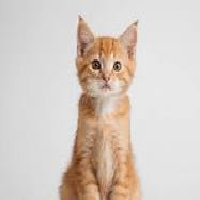

In [15]:
img

In [16]:
# Prepare the image array
img_array = image.img_to_array(img)

# Add a batch dimension -> (1, height, width, channels)
img_array = tf.expand_dims(img_array, axis=0)
data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

for i in range(10):
    # Apply augmentation (calling the pipeline directly handles the batch)
    augmented_batch = data_augmentation(img_array)
    
    # Remove the batch dimension to get back a 3D array -> (height, width, channels)
    # Also ensure the values are converted to integers/uint8 format for saving
    new_img_array = tf.squeeze(augmented_batch, axis=0).numpy().astype("uint8")
    
    # Save the array directly as an image file
    image.save_img(f"augmented_data/aug_img_{i}.jpg", new_img_array)

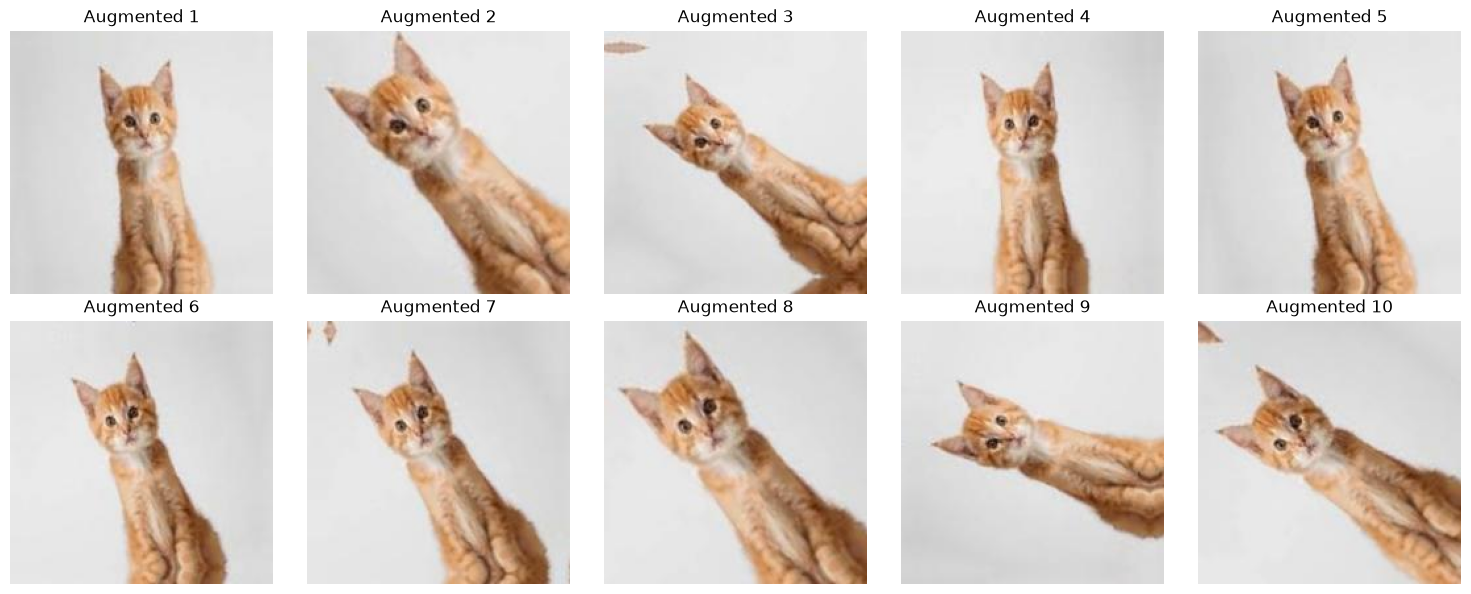

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Flatten the 2D array of axes to a 1D list so it's easier to loop through
axes = axes.flatten()

# 3. Loop through and plot each of the 10 images
for i in range(10):
    # Construct the exact file path matching the saved names
    img_path = f"augmented_data/aug_img_{i}.jpg"
    
    # Load the image using Keras utility
    img = image.load_img(img_path)
    
    # Display the image on the corresponding subplot axis
    axes[i].imshow(img)
    axes[i].set_title(f"Augmented {i+1}")
    axes[i].axis('off')  # Turn off the pixel coordinate axes for a cleaner look

# 4. Automatically adjust layout spacing and show the plot
plt.tight_layout()
plt.show()

# Now How to use it in the Neural Network

to see that let's use the Day 20's Model

In [ ]:
CNN = keras.Sequential([

    layers.Input(shape = (200, 200, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, kernel_size=(3,3),padding="valid",activation="relu",input_shape=(256,256,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2),strides=2),
    layers.Dropout(0.3),

    layers.Conv2D(64, kernel_size=(3,3),padding="valid",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2),strides=2),
    layers.Dropout(0.3),

    layers.Conv2D(128, kernel_size=(3,3),padding="valid",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2),strides=2),
    layers.Dropout(0.3),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64,activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1,activation="sigmoid")

])